# Проект: Исследование рынка видеоигр (EDA & Статистика)

**Цель:** Провести разведочный анализ данных (EDA) исторических продаж видеоигр (с объемом тиража >100 тыс. копий) и детально изучить показатели издателя Nintendo.

### План анализа:
1. **Предобработка данных:** Загрузка датасета, анализ структуры, проверка типов переменных и удаление пропусков.
2. **Описательная статистика:** Расчет метрик для переменной `Year` и визуализация распределения релизов по годам.
3. **Анализ лидеров рынка:** Определение топ-платформ и топ-издателей по количеству выпущенных игр.
4. **Региональный анализ Nintendo:** Поиск региона (NA, EU, JP, Other) с наибольшим медианным значением продаж игр Nintendo.
5. **Продажи Nintendo в Японии:** Расчет среднего, медианы и IQR для японских продаж в разрезе жанров.
6. **Анализ временных рядов:** Визуализация динамики мировых продаж (`Global_Sales`) по годам для жанров *Fighting, Simulation, Platform, Racing, Sports*. Определение пиковых периодов для жанра *Sports*.

### Словарь данных:
* `Rank` — место в топе продаж | `Name` — название | `Platform` — консоль | `Year` — год релиза | `Genre` — жанр | `Publisher` — издатель.
* `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales` — продажи по регионам (млн копий).
* `Global_Sales` — суммарные мировые продажи (млн копий).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import mode

sns.set_theme(
    style='whitegrid',
    rc={
       'figure.figsize': (16, 6),            # Размер холста (ширина, высота)
        'axes.grid': True,                   # Включаем сетку принудительно
        'grid.alpha': 0.3,                   # Делаем сетку легкой и полупрозрачной
        'grid.linestyle': '--',              # Делаем сетку пунктирной
        'axes.titlesize': 14,                # Размер шрифта для заголовков графиков
        'axes.titleweight': 'bold',          # Жирные заголовки
        'axes.labelsize': 12,                # Размер шрифта для подписей осей X и Y
    }
)

## Шаг 1. Предобработка данных
- Загрузка датасета
- анализ структуры
- проверка типов переменных
- удаление пропусков

In [2]:
# загрузка датасета
df = pd.read_csv(r'..\data\DF_games.csv')
# анализ структуры
df.head(10)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
5,6,Tetris,GB,1989.0,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26
6,7,New Super Mario Bros.,DS,2006.0,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
7,8,Wii Play,Wii,2006.0,Misc,Nintendo,14.03,9.20,2.93,2.85,29.02
8,9,New Super Mario Bros. Wii,Wii,2009.0,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62
9,10,Duck Hunt,NES,1984.0,Shooter,Nintendo,26.93,0.63,0.28,0.47,28.31


In [3]:
# проверка типов переменных
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB


In [4]:
# Проверка количества пропусков
df.isna().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [5]:
# Удаление пропусков
df.dropna(inplace=True)
df.isna().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [6]:
df.shape

(16291, 11)

In [7]:
df.Year = df.Year.astype(int) # Приведение года релиза к целочисленному типу
df.dtypes

Rank              int64
Name                str
Platform            str
Year              int64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

### Вывод по предобработке данных:
В ходе очистки данных были удалены строки с пропущенными значениями в полях `Year` и `Publisher` (около 2% от общего объема данных), что не повлияет на репрезентативность выборки. Поле `Year` успешно приведено к типу `int` для корректного отображения временных периодов на графиках.

## Шаг. 2 **Описательная статистика:**
- Расчет метрик для переменной `Year`
- визуализация распределения релизов по годам.

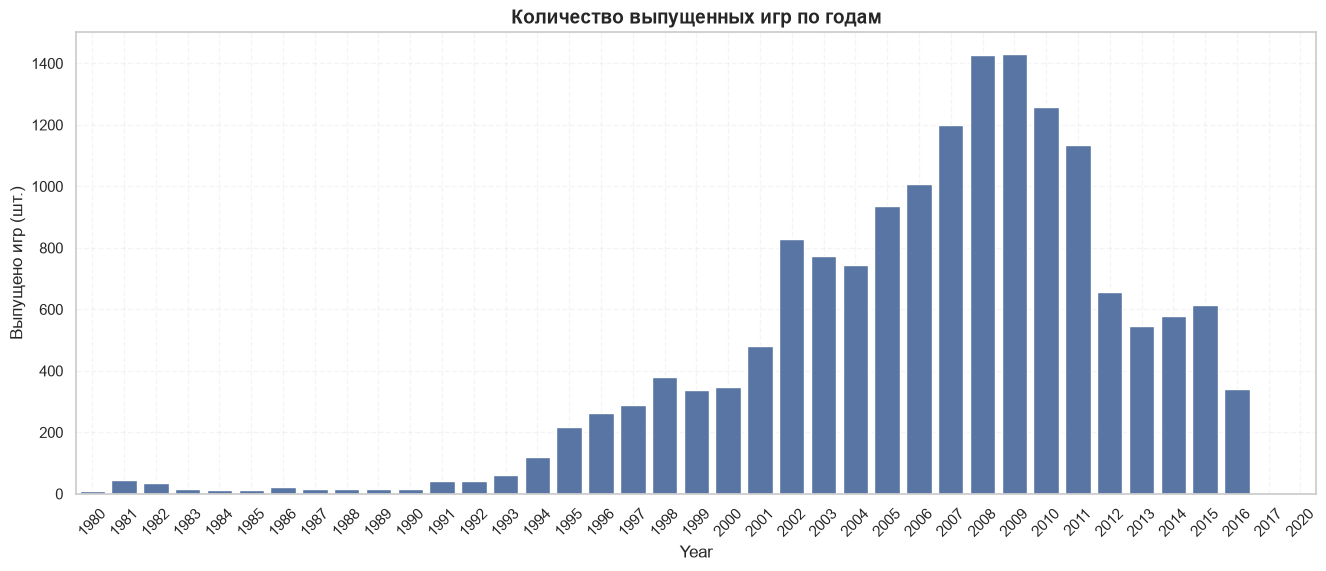

In [8]:
sns.countplot(data=df, x='Year')
plt.xticks(rotation=45)
plt.title('Количество выпущенных игр по годам')
plt.ylabel('Выпущено игр (шт.)')
plt.grid(True,alpha=0.2)


plt.show()

In [9]:
df.Year.describe() # Описательная статистика для поля 'Year'

count    16291.000000
mean      2006.405561
std          5.832412
min       1980.000000
25%       2003.000000
50%       2007.000000
75%       2010.000000
max       2020.000000
Name: Year, dtype: float64

In [10]:
df.query("Year <= 2007").shape[0]/16291,df.query("Year > 2007").shape[0]/16291

(0.5093609968694371, 0.4906390031305629)

In [11]:
mode(df.Year)

ModeResult(mode=np.int64(2009), count=np.int64(1431))

### Интерпретация описательных характеристик `Year`:
* **Объем выборки:** Анализ проведен по **16 291** игре (после очистки пропусков).
* **Временной охват:** В датасете представлены игры за 40-летний период — с **1980** по **2020** год.
* **Центральная тенденция:** Средний год выпуска игры — **2006**, а медианный — **2007** (половина всех игр в выборке вышла до 2007 года).
* **Плотность распределения:** Стандартное отклонение составляет **5.83 года**. Это говорит о том, что основная активность игрового рынка и подавляющее большинство релизов пришлись на период **2000–2012 гг.**, что также наглядно подтверждается графиком распределения.


## Шаг. 3 **Анализ лидеров рынка:**
Определение количества выпущенных игр
- топ-платформ
- топ-издателей

In [12]:
# Выводим топ 5 платформ по доли выпущенных игр
platform = df.Platform.value_counts(normalize=True).mul(100).to_frame('pct').reset_index()
platform.head()

,Platform,pct
0,DS,13.080842
1,PS2,13.056289
2,PS3,8.004420
3,Wii,7.918483
4,X360,7.574735


In [13]:
# Выводим топ 5 издателей по доли выпущенных игр
publisher_top = df.Publisher.value_counts(normalize=True).mul(100).to_frame('pct').reset_index()
publisher_top.head()

,Publisher,pct
0,Electronic Arts,8.219262
1,Activision,5.929654
2,Namco Bandai Games,5.696397
3,Ubisoft,5.635013
4,Konami Digital Entertainment,5.051869


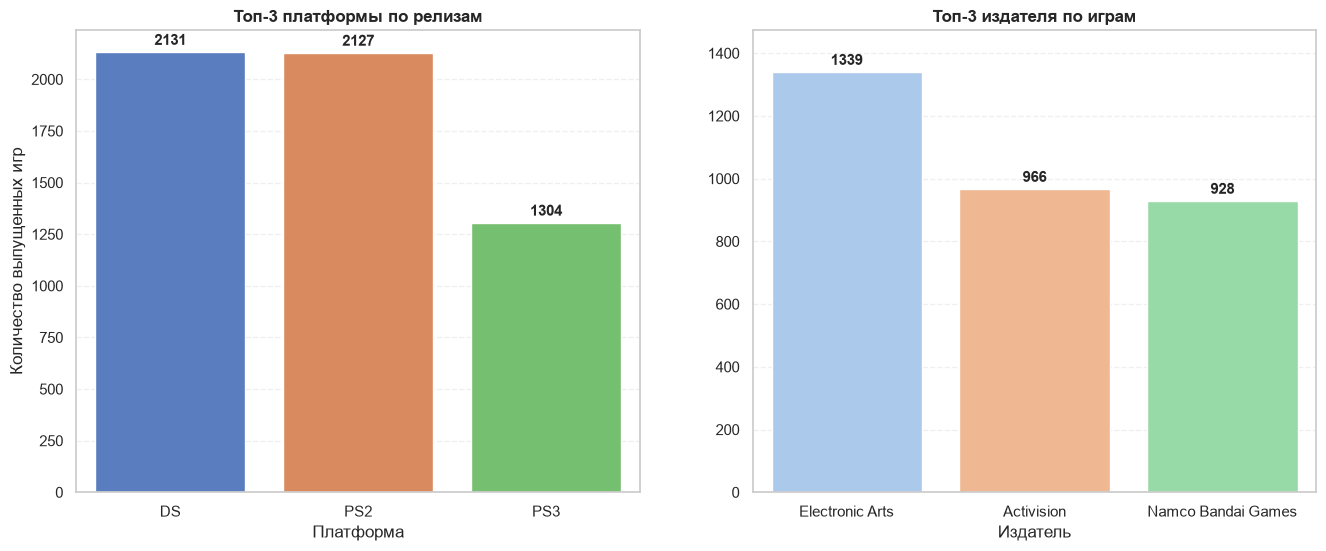

In [14]:
# Подготовка данных для обоих графиков
top_platform = df['Platform'].value_counts().head(3).reset_index()
top_platform.columns = ['Platform', 'Count']

top_publisher = df['Publisher'].value_counts().head(3).reset_index()
top_publisher.columns = ['Publisher', 'Count']

fig, axes = plt.subplots(nrows=1, ncols=2)

# ЛЕВЫЙ ГРАФИК
sns.barplot(data=top_platform, x='Platform', y='Count', ax=axes[0], palette='muted', hue='Platform', legend=False)
axes[0].set_title('Топ-3 платформы по релизам', fontsize=12, weight='bold')
axes[0].set_xlabel('Платформа')
axes[0].set_ylabel('Количество выпущенных игр')

for container in axes[0].containers:
    axes[0].bar_label(container, padding=3, fontsize=11, weight='bold')


# ПРАВЫЙ ГРАФИК
sns.barplot(data=top_publisher, x='Publisher', y='Count', ax=axes[1], palette='pastel', hue='Publisher', legend=False)
axes[1].set_title('Топ-3 издателя по играм', fontsize=12, weight='bold')
axes[1].set_xlabel('Издатель')
axes[1].set_ylabel('')

for container in axes[1].containers:
    axes[1].bar_label(container, padding=3, fontsize=11, weight='bold')
# Делаем запас по высоте для правого графика
axes[1].set_ylim(0, top_publisher['Count'].max() * 1.1)


plt.show()

### Вывод по лидерам рынка:
* **Платформы:** Абсолютное первенство по количеству релизов удерживают портативная консоль **Nintendo DS** (13.08%) и домашняя приставка **PlayStation 2** (13.05%). Высокая плотность релизов на этих платформах объясняется их колоссальной популярностью и длительным жизненным циклом в эпоху 2000-х годов. На третьем месте идет **PlayStation 3** (8%).
* **Издатели:** Самым активным издателем в датасете является **Electronic Arts** (1339 игр), за которым с большим отрывом следуют **Activision** (966) и **Namco Bandai Games** (928).

## Шаг 4. Региональный анализ продаж Nintendo
- Поиск региона (NA, EU, JP, Other) с наибольшим медианным значением продаж игр Nintendo.

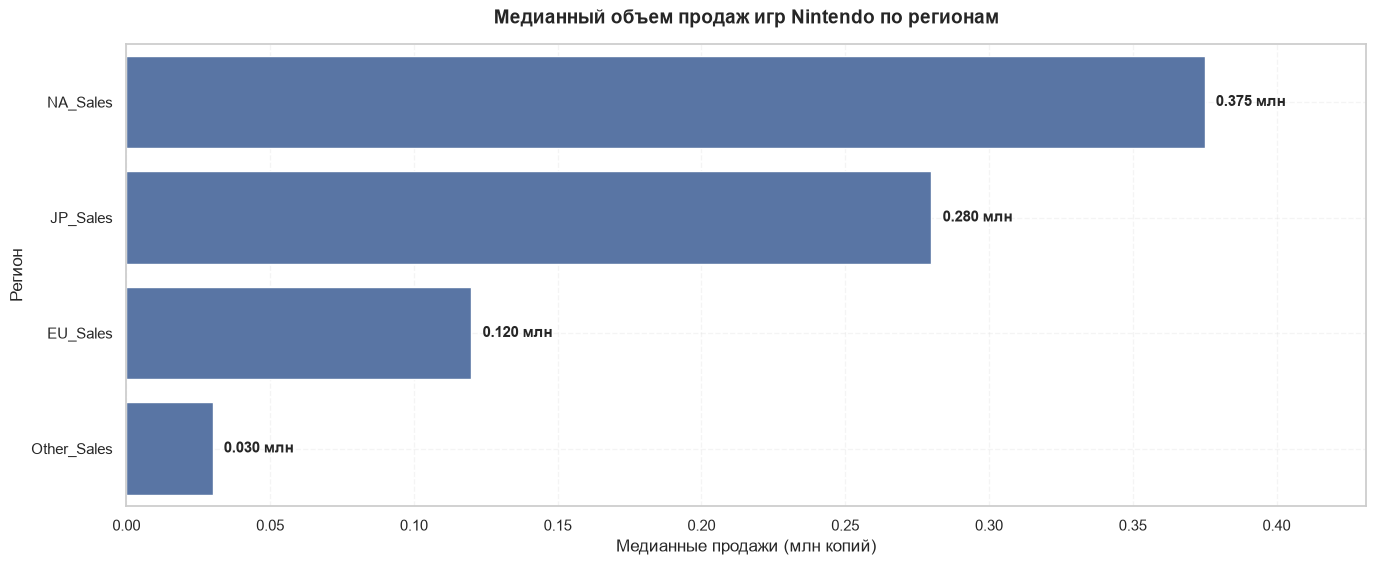

In [15]:
df_Nintendo = df[df['Publisher'] == 'Nintendo']
df_melted   = df_Nintendo.melt(
    id_vars=['Name'],
    value_vars=['NA_Sales','EU_Sales','JP_Sales','Other_Sales'],
    var_name='Region',
    value_name='Sales',
)
region_order = df_melted.groupby('Region')['Sales'].median().sort_values(ascending=False).reset_index()

ax = sns.barplot(data=region_order, x='Sales',y='Region')
plt.title('Медианные продажи по регионам (от большего к наименьшему)')

ax.bar_label(ax.containers[0], padding=8, fmt='%.3f млн', fontsize=11, weight='bold')

plt.xlim(0, region_order['Sales'].max() * 1.15)

plt.title('Медианный объем продаж игр Nintendo по регионам', fontsize=14, pad=15, weight='bold')
plt.xlabel('Медианные продажи (млн копий)', fontsize=12)
plt.ylabel('Регион', fontsize=12)
plt.grid(True,alpha=0.2)


plt.show()

### Вывод по региональным продажам Nintendo:
* Максимальный коммерческий успех игр от издательства Nintendo зафиксирован на рынке **Северной Америки (NA_Sales)**. Медианный объем продаж на одну игру здесь составляет **0.375 млн копий**.
* На втором месте находится домашний рынок **Японии (JP_Sales)** с медианой **0.280 млн копий**.
* **Европа (EU_Sales)** демонстрирует более скромные показатели (медиана — 0.120 млн копий), а регион **Other_Sales** ожидаемо замыкает список с минимумом в 0.030 млн копий.


## Шаг. 5 **Продажи Nintendo в Японии:**
Расчет для японских продаж в разрезе жанров:
 - среднего
 - медианы
  - IQR

In [16]:
df_jp_sales = df[(df['Publisher'] == 'Nintendo') & (df['JP_Sales'] > 0)][['JP_Sales','Genre','Name']]


def iqr(series):
    return series.quantile(0.75) - series.quantile(0.25)

df_jp_sales_gb = df_jp_sales.groupby('Genre')['JP_Sales'].agg(['mean','median',iqr])
df_jp_sales_gb.columns = ['Среднее','Медиана','Межквартильный размах (IQR)']
df_jp_sales_gb = df_jp_sales_gb.reset_index()

df_jp_sales_gb = df_jp_sales_gb.sort_values(by=['Медиана', 'Среднее'], ascending=False)
display(df_jp_sales_gb)

,Genre,Среднее,Медиана,Межквартильный размах (IQR)
2,Fighting,0.933750,0.645,1.1000
4,Platform,0.956636,0.550,0.8450
9,Simulation,0.946000,0.530,0.8600
7,Role-Playing,1.051031,0.390,0.5800
6,Racing,0.942581,0.380,0.9850
10,Sports,0.779783,0.355,0.7050
3,Misc,0.635057,0.300,0.7100
5,Puzzle,0.553582,0.300,0.5150
11,Strategy,0.387407,0.260,0.4700
0,Action,0.416571,0.215,0.4225


### Выводы по структуре рынка Японии (для игр Nintendo):

1. **Лидеры по типичным продажам (Медиана):**
   Самым стабильно успешным жанром в Японии для Nintendo является **Fighting** с медианой **0.645 млн копий**, за ним идут **Platform** (0.550 млн) и **Simulation** (0.530 млн). Именно в этих жанрах типичная, среднестатистическая игра приносит наибольший объем продаж.

2. **Влияние скрытых супер-хитов на Среднее значение:**
   Жанр **Role-Playing** занимает лишь 4-е место по медиане (0.390 млн), но лидирует по среднему значению (**1.051 млн копий**). Существенный разрыв между средним и медианой (почти в 3 раза) — это классический признак наличия **мощных положительных выбросов**. Это означает, что в данном жанре у Nintendo есть несколько аномально успешных игр-флагманов, которые сильно завышают среднее арифметическое, в то время как основная масса RPG продается в пределах нормы.

3. **Анализ вариативности и риска (IQR):**
   * Жанр **Fighting** обладает самым высоким межквартильным размахом (**IQR = 1.100**). Это указывает на высокую изменчивость данных и разброс продаж внутри жанра: здесь соседствуют как скромные релизы, так и масштабные хиты.
   * Жанры **Shooter** (IQR = 0.195) и **Adventure** (IQR = 0.230) имеют самую низкую вариативность — продажи внутри этих жанров стабильны, но находятся на минимальном уровне.


## 6. **Анализ временных рядов:**
Визуализация динамики мировых продаж (`Global_Sales`) по годам для жанров *Fighting, Simulation, Platform, Racing, Sports*. Определение пиковых периодов для жанра *Sports*.

In [17]:
ganre = ['Fighting','Simulation','Platform', 'Racing', 'Sports']
genre_analysis = df['Genre'].isin(ganre)
genre_analysis = df[genre_analysis]
genre_analysis

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
6,7,New Super Mario Bros.,DS,2006,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
...,...,...,...,...,...,...,...,...,...,...,...
16587,16590,Mezase!! Tsuri Master DS,DS,2009,Sports,Hudson Soft,0.00,0.00,0.01,0.00,0.01
16592,16595,Plushees,DS,2008,Simulation,Destineer,0.01,0.00,0.00,0.00,0.01
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01


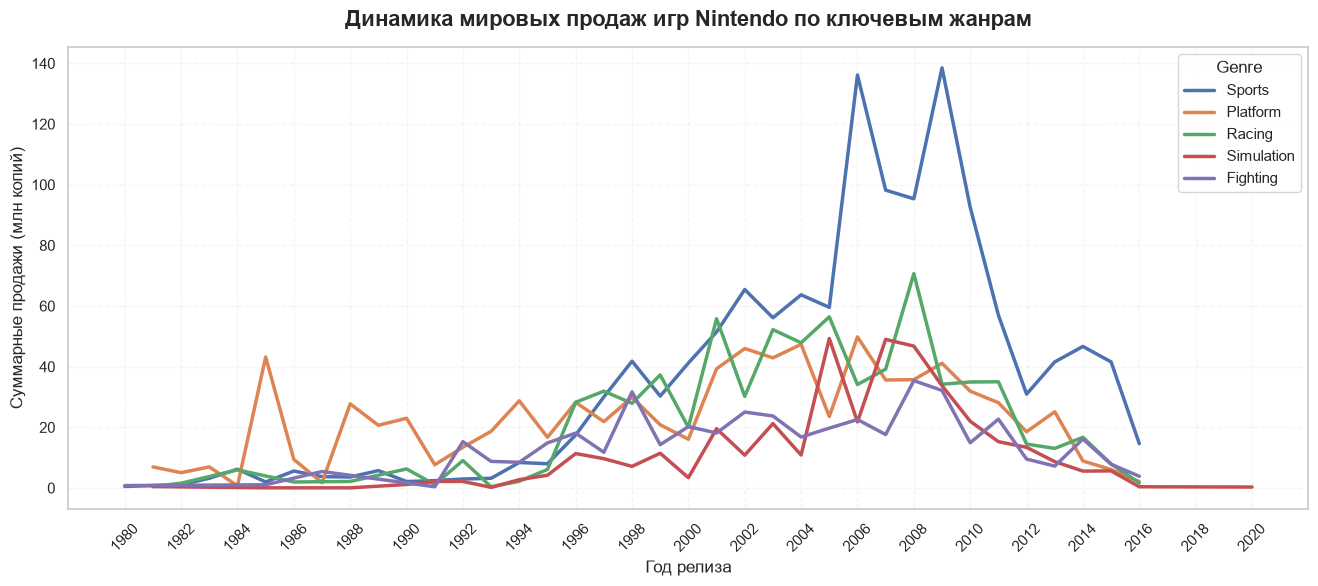

In [18]:
sns.lineplot(
    data=genre_analysis,
    y='Global_Sales',
    x='Year',
    hue='Genre',
    estimator='sum',
    errorbar=None,
    linewidth=2.5
)

plt.title('Динамика мировых продаж игр Nintendo по ключевым жанрам', fontsize=16, weight='bold', pad=15)
plt.xlabel('Год релиза', fontsize=12)
plt.ylabel('Суммарные продажи (млн копий)', fontsize=12)

plt.xticks(np.arange(1980,2021,2),rotation=45)
plt.grid(True,alpha=0.2)

plt.show()

In [19]:
genre_analysis2006 = genre_analysis[genre_analysis['Year'] == 2006].sort_values(by=['Global_Sales'],ascending=False).head(1)
genre_analysis2006

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74


In [20]:
genre_analysis2009 = genre_analysis[genre_analysis['Year'] == 2009].sort_values(by=['Global_Sales'],ascending=False).head(1)
genre_analysis2009

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.0


### Вывод по динамике мировых продаж:
Линейный график в Ячейке №19 наглядно демонстрирует общие тренды игровой индустрии для пяти выбранных жанров:
* Жанр **Platform** исторически доминировал на рынке в 80-х и начале 90-х годов, формируя первые крупные пики мировых продаж.
* Жанр **Action** (если бы он был на графике) или **Sports** показывают взрывной рост в середине 2000-х.
* В период **2006–2009 годов** зафиксирован аномальный всплеск мировых продаж в жанре **Sports**. Абсолютный исторический пик на графике приходится на **2006 год** — в масштабах всего рынка это обусловлено выходом игры *Wii Sports*, которая разошлась рекордным тиражом в 82.74 млн копий и попала в общую статистику, задрав синюю линию вверх. Второй локальный пик в 2009 году связан с выходом *Wii Sports Resort* (33 млн копий).
* После 2010 года по всем пяти жанрам наблюдается заметный спад глобальных продаж на физических носителях.
